# Government vs Opposition Factuality Over Time

Compares factuality scores between government and opposition speakers
in Ontario and Quebec legislative health debates, 1985-2026.

Background shading indicates governing party for each jurisdiction.
Two lines per panel: government speakers (solid) and opposition speakers (dashed).

In [1]:
import json
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

REPO = '/Users/caprice/MiscellaneousProjects/legislative-health-factuality'
os.makedirs(f'{REPO}/figures', exist_ok=True)

print('Loading data...')

Loading data...


In [2]:
# ── Governing periods ─────────────────────────────────────────────────────────

ONTARIO_GOVS = [
    (1985, 1985, 'PC',      '#4393C3'),
    (1985, 1990, 'Liberal', '#D6604D'),
    (1990, 1995, 'NDP',     '#F4A582'),
    (1995, 2003, 'PC',      '#4393C3'),
    (2003, 2018, 'Liberal', '#D6604D'),
    (2018, 2027, 'PC',      '#4393C3'),
]

ONTARIO_GOV_PARTIES = {
    range(1985, 1986): 'Progressive Conservative Party of Ontario',
    range(1985, 1990): 'Ontario Liberal Party',
    range(1990, 1995): 'New Democratic Party of Ontario',
    range(1995, 2003): 'Progressive Conservative Party of Ontario',
    range(2003, 2018): 'Ontario Liberal Party',
    range(2018, 2027): 'Progressive Conservative Party of Ontario',
}

QUEBEC_GOVS = [
    (1985, 1994, 'Liberal', '#D6604D'),
    (1994, 2003, 'PQ',      '#74ADD1'),
    (2003, 2012, 'Liberal', '#D6604D'),
    (2012, 2014, 'PQ',      '#74ADD1'),
    (2014, 2018, 'Liberal', '#D6604D'),
    (2018, 2027, 'CAQ',     '#78C679'),
]

def get_ontario_gov_party(year):
    if year < 1986: return 'Progressive Conservative Party of Ontario'
    if year < 1990: return 'Ontario Liberal Party'
    if year < 1995: return 'New Democratic Party of Ontario'
    if year < 2003: return 'Progressive Conservative Party of Ontario'
    if year < 2018: return 'Ontario Liberal Party'
    return 'Progressive Conservative Party of Ontario'

def get_quebec_gov_party(year):
    if year < 1994: return 'Liberal'
    if year < 2003: return 'Parti Quebecois'
    if year < 2012: return 'Liberal'
    if year < 2014: return 'Parti Quebecois'
    if year < 2018: return 'Liberal'
    return 'Coalition Avenir Quebec'

print('Governing periods defined')

Governing periods defined


In [3]:
# ── Load Ontario DB1 and compute gov vs opp by year ───────────────────────────

with open(f'{REPO}/data/dbpedia_pipeline/ontario/db1_claim_bearing.json') as f:
    ont_db1 = json.load(f)

ont_rows = []
for s in ont_db1:
    date = s.get('date', '')
    if not date: continue
    year = int(date[:4])
    party = s.get('party', '')
    is_minister = s.get('is_minister', False)
    supported = s.get('supported', False)
    gov_party = get_ontario_gov_party(year)
    
    # Government = member of governing party
    is_gov = gov_party.lower() in party.lower() if party else False
    
    ont_rows.append({
        'year': year,
        'is_gov': is_gov,
        'supported': int(supported)
    })

ont_df = pd.DataFrame(ont_rows)
ont_gov_yearly = ont_df[ont_df['is_gov']].groupby('year')['supported'].agg(['mean','count']).reset_index()
ont_opp_yearly = ont_df[~ont_df['is_gov']].groupby('year')['supported'].agg(['mean','count']).reset_index()
ont_gov_yearly.columns = ['year','mean','n']
ont_opp_yearly.columns = ['year','mean','n']

print(f'Ontario: {len(ont_df):,} sentences')
print(f'Government: {ont_df["is_gov"].sum():,} | Opposition: {(~ont_df["is_gov"]).sum():,}')

Ontario: 283,033 sentences
Government: 87,794 | Opposition: 195,239


In [4]:
# ── Load Quebec DB1 and compute gov vs opp by year ────────────────────────────

with open(f'{REPO}/data/dbpedia_pipeline/quebec/db1_claim_bearing.json') as f:
    qc_db1 = json.load(f)

qc_rows = []
for s in qc_db1:
    date = s.get('date', '')
    if not date: continue
    year = int(date[:4])
    party = s.get('party', '')
    supported = s.get('supported', False)
    gov_party = get_quebec_gov_party(year)
    is_gov = gov_party.lower().split()[0] in party.lower() if party else False
    
    qc_rows.append({
        'year': year,
        'is_gov': is_gov,
        'supported': int(supported)
    })

qc_df = pd.DataFrame(qc_rows)
# Only keep health-debate sentences (in annotated set)
with open(f'{REPO}/data/dbpedia_pipeline/quebec/annotated_sentences.json') as f:
    qc_annotated_ids = {s['sentence_id'] for s in json.load(f)}

qc_gov_yearly = qc_df[qc_df['is_gov']].groupby('year')['supported'].agg(['mean','count']).reset_index()
qc_opp_yearly = qc_df[~qc_df['is_gov']].groupby('year')['supported'].agg(['mean','count']).reset_index()
qc_gov_yearly.columns = ['year','mean','n']
qc_opp_yearly.columns = ['year','mean','n']

print(f'Quebec: {len(qc_df):,} sentences')
print(f'Government: {qc_df["is_gov"].sum():,} | Opposition: {(~qc_df["is_gov"]).sum():,}')

Quebec: 334,522 sentences
Government: 136,949 | Opposition: 197,573


In [5]:
# ── Smooth with rolling average for readability ───────────────────────────────

def smooth(df, window=3):
    df = df.copy()
    df['mean_smooth'] = df['mean'].rolling(window, center=True, min_periods=1).mean()
    return df

ont_gov_s = smooth(ont_gov_yearly)
ont_opp_s = smooth(ont_opp_yearly)
qc_gov_s  = smooth(qc_gov_yearly)
qc_opp_s  = smooth(qc_opp_yearly)

print('Smoothing applied (3-year rolling average)')

Smoothing applied (3-year rolling average)


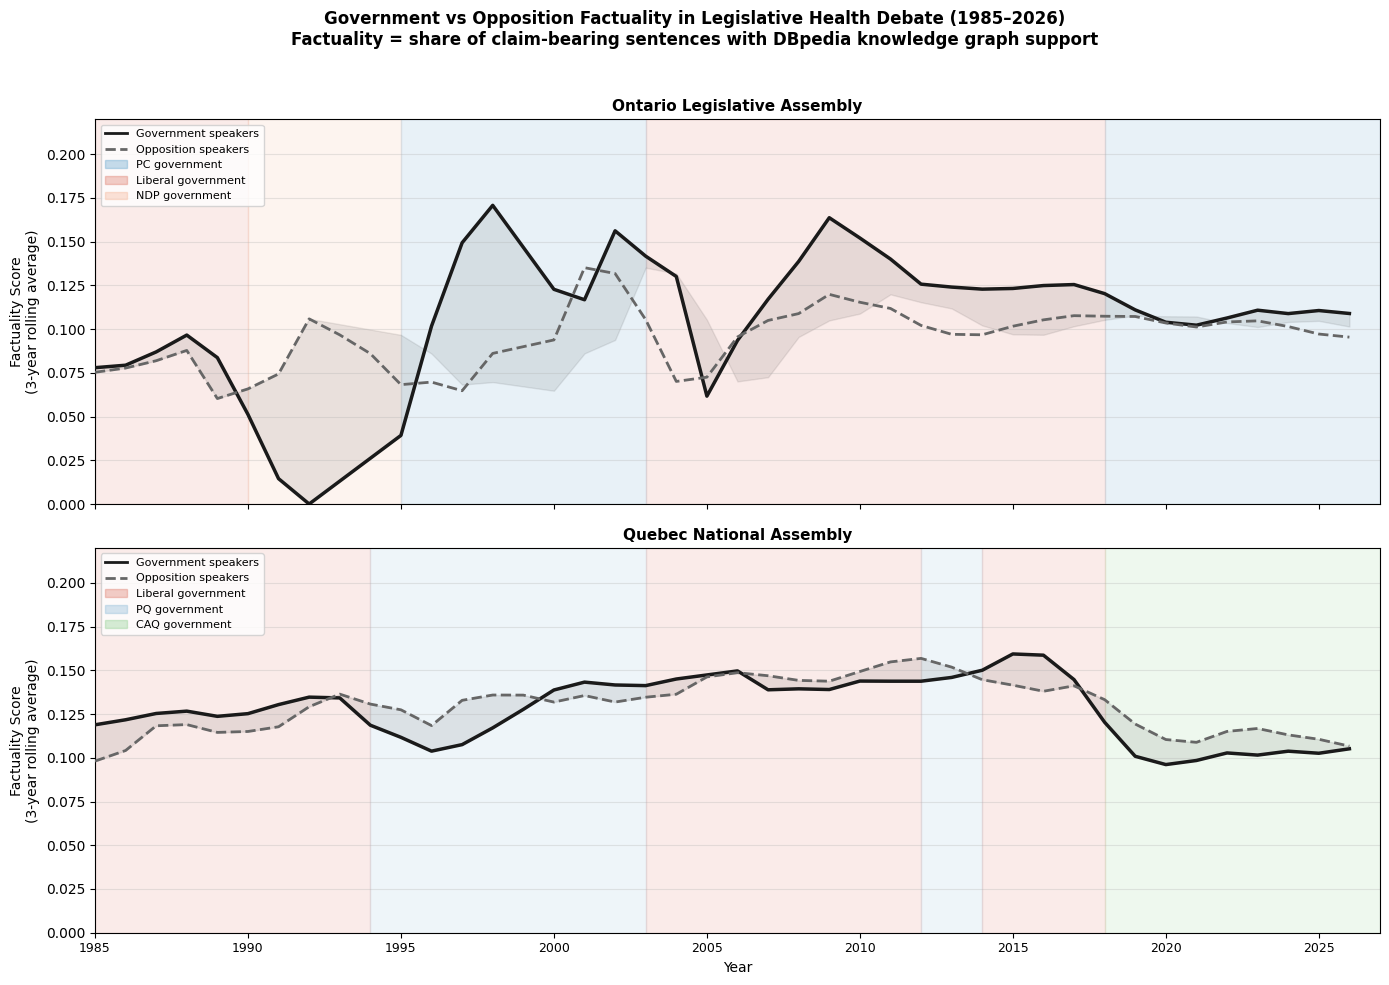

Saved to figures/gov_vs_opp_over_time.png


In [6]:
# ── FIGURE: Government vs Opposition Factuality Over Time ─────────────────────

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
fig.suptitle(
    'Government vs Opposition Factuality in Legislative Health Debate (1985–2026)\n'
    'Factuality = share of claim-bearing sentences with DBpedia knowledge graph support',
    fontsize=12, fontweight='bold', y=0.98
)

# ── Ontario panel ─────────────────────────────────────────────────────────────
ax = axes[0]
for start, end, party, color in ONTARIO_GOVS:
    ax.axvspan(start, end, alpha=0.12, color=color)

ax.plot(ont_gov_s['year'], ont_gov_s['mean_smooth'], color='#1A1A1A', linewidth=2.5,
        label='Government speakers', zorder=3)
ax.plot(ont_opp_s['year'], ont_opp_s['mean_smooth'], color='#666666', linewidth=2,
        linestyle='--', label='Opposition speakers', zorder=3)
ax.fill_between(ont_gov_s['year'], ont_gov_s['mean_smooth'],
                ont_opp_s['mean_smooth'].reindex(ont_gov_s.index),
                alpha=0.08, color='black', label='Gov-Opp gap')

ax.set_ylabel('Factuality Score\n(3-year rolling average)', fontsize=10)
ax.set_title('Ontario Legislative Assembly', fontsize=11, fontweight='bold')
ax.set_ylim(0, 0.22)
ax.grid(axis='y', alpha=0.3)

pc_patch  = mpatches.Patch(color='#4393C3', alpha=0.3, label='PC government')
lib_patch = mpatches.Patch(color='#D6604D', alpha=0.3, label='Liberal government')
ndp_patch = mpatches.Patch(color='#F4A582', alpha=0.3, label='NDP government')
gov_line  = plt.Line2D([0],[0], color='#1A1A1A', linewidth=2, label='Government speakers')
opp_line  = plt.Line2D([0],[0], color='#666666', linewidth=2, linestyle='--', label='Opposition speakers')
ax.legend(handles=[gov_line, opp_line, pc_patch, lib_patch, ndp_patch],
          fontsize=8, loc='upper left')

# ── Quebec panel ──────────────────────────────────────────────────────────────
ax = axes[1]
for start, end, party, color in QUEBEC_GOVS:
    ax.axvspan(start, end, alpha=0.12, color=color)

ax.plot(qc_gov_s['year'], qc_gov_s['mean_smooth'], color='#1A1A1A', linewidth=2.5,
        label='Government speakers', zorder=3)
ax.plot(qc_opp_s['year'], qc_opp_s['mean_smooth'], color='#666666', linewidth=2,
        linestyle='--', label='Opposition speakers', zorder=3)
ax.fill_between(qc_gov_s['year'], qc_gov_s['mean_smooth'],
                qc_opp_s['mean_smooth'].reindex(qc_gov_s.index),
                alpha=0.08, color='black')

ax.set_ylabel('Factuality Score\n(3-year rolling average)', fontsize=10)
ax.set_xlabel('Year', fontsize=10)
ax.set_title('Quebec National Assembly', fontsize=11, fontweight='bold')
ax.set_ylim(0, 0.22)
ax.grid(axis='y', alpha=0.3)

lib_patch = mpatches.Patch(color='#D6604D', alpha=0.3, label='Liberal government')
pq_patch  = mpatches.Patch(color='#74ADD1', alpha=0.3, label='PQ government')
caq_patch = mpatches.Patch(color='#78C679', alpha=0.3, label='CAQ government')
gov_line  = plt.Line2D([0],[0], color='#1A1A1A', linewidth=2, label='Government speakers')
opp_line  = plt.Line2D([0],[0], color='#666666', linewidth=2, linestyle='--', label='Opposition speakers')
ax.legend(handles=[gov_line, opp_line, lib_patch, pq_patch, caq_patch],
          fontsize=8, loc='upper left')

for ax in axes:
    ax.set_xlim(1985, 2027)
    ax.set_xticks(range(1985, 2027, 5))
    ax.tick_params(axis='x', labelsize=9)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(f'{REPO}/figures/gov_vs_opp_over_time.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved to figures/gov_vs_opp_over_time.png')